# Diagnóstico de marca empleadora — BMW Group vs. peers de automoción
## NLP con sentimiento + BERTopic sobre reseñas de Glassdoor

**Objetivo de negocio.** RRHH quiere entender cómo se posiciona **BMW Group** como empleador frente a competidores del mismo sector, identificar fortalezas aprovechables en employer branding y detectar áreas de mejora relacionadas con atracción y retención de talento.

**Empresa objetivo:** BMW Group  
**Peers:** Mercedes-Benz Group, Volvo Group, Jaguar Land Rover y Tesla.

La selección combina fabricantes comparables con BMW y un competidor con una propuesta tecnológica y organizativa diferenciada (Tesla). Todos compiten por perfiles similares —ingeniería, tecnología, producción, operaciones, diseño y gestión—, por lo que la comparación es relevante desde el punto de vista de talento.

**Nota sobre la selección de peers.** Volkswagen Group se valoró inicialmente como peer válido, pero disponía de un volumen de reseñas claramente menor que el resto del grupo seleccionado. Incluirlo habría reducido la muestra equilibrada de NLP a unas 650 reseñas por empresa. Jaguar Land Rover permite mantener una comparación dentro de automoción y trabajar con unas 900 reseñas por empresa, aumentando la información disponible sin dar más peso a las empresas con más opiniones. Esta decisión práctica se reconoce también como una limitación: los resultados dependen del conjunto de peers elegido.

**Pregunta central:**  
> ¿Cómo se posiciona BMW como empleador frente a estos peers y qué fortalezas o debilidades debería priorizar RRHH?

### Estructura del notebook
1. Carga, calidad y preparación de datos  
2. EDA de negocio  
3. Muestra equilibrada para NLP  
4. Control de calidad del sentimiento en pros y cons  
5. Topic modeling con BERTopic  
6. Revisión y etiquetado manual de topics  
7. Comparación con peers: porcentajes, balance neto y gap  
8. Empleados actuales vs. antiguos  
9. Matriz de priorización para RRHH  
10. Extra: evolución temporal de categorías  
11. Conclusiones, recomendaciones y limitaciones

> **Nota metodológica.** Tras varias iteraciones de calibración, el modelado queda fijado y la interpretación final distingue entre **fortalezas reales**, **ventajas relativas con balance todavía negativo**, **debilidades relativas** y **oportunidades de employer branding**. Las señales se triangulan con rating, recomendación y diferencias entre empleados actuales y antiguos antes de proponer un máximo de **tres recomendaciones concretas para RRHH**.


---
## 0. Entorno e instalación

El profesor recomienda **Google Colab con GPU** porque tanto el transformer de sentimiento como BERTopic pueden ser costosos. Sin embargo, la ejecución local en VS Code ha sido viable: DistilBERT tarda alrededor de **5 minutos en CPU** para 9.000 textos y BERTopic es bastante más rápido.

Por tanto, mantenemos VS Code como entorno principal y dejamos Colab como alternativa. Los tiempos de sentimiento y topic modeling se miden con `perf_counter()` para dejar constancia del coste computacional real.

**Decisión técnica con sentido de negocio:** usamos modelos preentrenados para dedicar el esfuerzo a interpretar la voz del empleado y comparar empresas, no a entrenar desde cero un modelo lingüístico que no aporta valor adicional al encargo de RRHH.


In [1]:
# En Google Colab, descomenta y ejecuta una sola vez si hace falta:
# !pip install -q pyarrow torch transformers bertopic sentence-transformers umap-learn hdbscan

# En VS Code estas librerías pueden instalarse desde el terminal con:
# python -m pip install pyarrow torch transformers bertopic sentence-transformers umap-learn hdbscan

In [2]:
from pathlib import Path
import re
import warnings
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_rows", 100)

SEED = 42
TARGET = "BMW-Group"
PEERS = [
    "Mercedes-Benz-Group",
    "Volvo-Group",
    "Jaguar-Land-Rover",
    "Tesla",
]
FIRMS = [TARGET] + PEERS
MAX_POR_EMPRESA = 900

print("Empresa objetivo:", TARGET)
print("Peers:", PEERS)

Empresa objetivo: BMW-Group
Peers: ['Mercedes-Benz-Group', 'Volvo-Group', 'Jaguar-Land-Rover', 'Tesla']


---
## 1. Carga y preparación

El fichero Parquet es grande, así que se carga **solo BMW y sus cuatro peers** mediante filtros. Esto reduce memoria y tiempo sin eliminar información relevante para la pregunta de negocio.

Para el **EDA** se conservan todas las reseñas disponibles de las cinco empresas. La muestra equilibrada se aplicará más adelante únicamente a las partes pesadas de NLP.

In [3]:
possible_paths = [
    Path("glassdoor_reviews_hr.parquet"),
    Path("/content/glassdoor_reviews_hr.parquet"),  # ruta habitual en Colab
]

DATA_PATH = next((p for p in possible_paths if p.exists()), None)
if DATA_PATH is None:
    candidates = list(Path(".").glob("*glassdoor*hr*.parquet"))
    if not candidates:
        raise FileNotFoundError(
            "No se encontró 'glassdoor_reviews_hr.parquet'. Coloca el fichero en la misma carpeta "
            "que el notebook o súbelo a la sesión de Colab."
        )
    DATA_PATH = candidates[0]

raw = pd.read_parquet(DATA_PATH, filters=[("firm", "in", FIRMS)])

print(f"Ruta utilizada: {DATA_PATH}")
print(f"Reseñas cargadas: {len(raw):,}")
print("\nReseñas disponibles por empresa:")
print(raw["firm"].value_counts().reindex(FIRMS))

Ruta utilizada: glassdoor_reviews_hr.parquet
Reseñas cargadas: 10,814

Reseñas disponibles por empresa:
firm
BMW-Group              1137
Mercedes-Benz-Group     930
Volvo-Group            1187
Jaguar-Land-Rover      2123
Tesla                  5437
Name: count, dtype: int64


In [4]:
print("Dimensiones:", raw.shape)
print("\nTipos de datos:")
display(raw.dtypes.to_frame("dtype"))

print("\nNulos por columna:")
calidad = pd.DataFrame({
    "n_nulos": raw.isna().sum(),
    "pct_nulos": (raw.isna().mean() * 100).round(2),
})
display(calidad)

print("\nPrimeras filas:")
display(raw.head())

Dimensiones: (10814, 7)

Tipos de datos:


,dtype
firm,object
date_review,object
current,object
overall_rating,float64
recommend,object
pros,object
cons,object



Nulos por columna:


,n_nulos,pct_nulos
firm,0,0.0
date_review,0,0.0
current,0,0.0
overall_rating,0,0.0
recommend,0,0.0
pros,0,0.0
cons,0,0.0



Primeras filas:


,firm,date_review,current,overall_rating,recommend,pros,cons
0,BMW-Group,2018-07-29,"Former Employee, more than 3 years",1.0,x,There are no Positives that apply.,"ALL - NO, Repeat, NO Human Resources policies are observed.\r\nALL Management Defrauding BMW and Empoyees"
1,BMW-Group,2018-07-30,"Former Employee, less than 1 year",5.0,v,- Great experience \r\n- Brilliant people to work with\r\n- Best way to get recognition from employers after completing internship,- Location - Farnborough\r\n- Very rigid corporate culture - difficult to have standard purchase orders approved
2,BMW-Group,2018-07-31,"Former Employee, less than 1 year",4.0,v,"Colourful workforce, very skilled and experienced with how the Press Shop ran, office engineers are willing to help fresh blood when pressed. Engaging workl...","Culture split between engineers and Press Line operators and associates, communication has problems between offices and workfloor."
3,BMW-Group,2018-08-02,"Former Employee, more than 10 years",5.0,v,The best company for the best experience!,Didn't drive enough. I wasn't an owner.
4,BMW-Group,2018-08-02,"Former Employee, more than 1 year",5.0,v,good experience in the project,none to be told during the project time


### 1.1 Limpieza mínima y variables derivadas

La columna `current` mezcla dos conceptos: situación del empleado y antigüedad. Los separamos porque RRHH necesita distinguir **empleados actuales** de **antiguos**, y la antigüedad puede utilizarse después como análisis adicional.

`recommend` se traduce a etiquetas legibles y los textos se limpian solo a nivel superficial: espacios, saltos de línea y nulos. **No eliminamos stopwords ni hacemos stemming antes de BERT/BERTopic**, porque los modelos de lenguaje aprovechan el contexto de la frase y una limpieza agresiva podría destruir información útil.

In [5]:
def extraer_situacion(valor):
    s = str(valor).strip().lower()
    if s.startswith("current"):
        return "Actual"
    if s.startswith("former"):
        return "Antiguo"
    return "Desconocido"


def extraer_antiguedad(valor):
    s = str(valor).strip()
    if "," in s:
        return s.split(",", 1)[1].strip()
    return "n/d"


def limpiar_texto(serie):
    return (
        serie.fillna("")
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )


df_full = raw.copy()
df_full["date_review"] = pd.to_datetime(df_full["date_review"], errors="coerce")
df_full["anio"] = df_full["date_review"].dt.year

df_full["situacion"] = df_full["current"].map(extraer_situacion)
df_full["antiguedad"] = df_full["current"].map(extraer_antiguedad)
df_full["recomienda"] = df_full["recommend"].map({"v": "Sí", "o": "Neutral", "x": "No"}).fillna("No disponible")

df_full["pros"] = limpiar_texto(df_full["pros"])
df_full["cons"] = limpiar_texto(df_full["cons"])

df_full["pros_valido"] = df_full["pros"].str.len().ge(3)
df_full["cons_valido"] = df_full["cons"].str.len().ge(3)

df_full["es_actual"] = df_full["situacion"].map({"Actual": 1.0, "Antiguo": 0.0})
df_full["es_antiguo"] = df_full["situacion"].map({"Actual": 0.0, "Antiguo": 1.0})
df_full["recomienda_si"] = df_full["recomienda"].map({"Sí": 1.0, "Neutral": 0.0, "No": 0.0})

print("Situación laboral:")
display(pd.crosstab(df_full["firm"], df_full["situacion"]))

print("\nTextos válidos por empresa:")
textos_validos = df_full.groupby("firm").agg(
    reseñas=("firm", "size"),
    pros_validos=("pros_valido", "sum"),
    cons_validos=("cons_valido", "sum"),
    ambos_validos=("firm", lambda x: 0),
)
# ambos_validos se calcula aparte para mantener el índice de empresa
ambos = df_full.assign(ambos=df_full["pros_valido"] & df_full["cons_valido"]).groupby("firm")["ambos"].sum()
textos_validos["ambos_validos"] = ambos
textos_validos = textos_validos.reindex(FIRMS)
display(textos_validos)

Situación laboral:


situacion,Actual,Antiguo
firm,,
BMW-Group,644,493
Jaguar-Land-Rover,1421,702
Mercedes-Benz-Group,533,397
Tesla,2975,2462
Volvo-Group,792,395



Textos válidos por empresa:


,reseñas,pros_validos,cons_validos,ambos_validos
firm,,,,
BMW-Group,1137,1137,1137,1137
Mercedes-Benz-Group,930,930,930,930
Volvo-Group,1187,1187,1187,1187
Jaguar-Land-Rover,2123,2123,2123,2123
Tesla,5437,5437,5437,5437


---
## 2. EDA de negocio

El EDA responde a cuatro preguntas sencillas para RRHH:

- ¿Cuántas reseñas tenemos de cada empresa?
- ¿Qué valoración media recibe cada empleador?
- ¿Qué porcentaje recomendaría trabajar allí?
- ¿Qué proporción de opiniones procede de empleados actuales y antiguos?

Después se estudia la evolución temporal del rating. Aquí usamos **todas las reseñas disponibles**, porque reducir el EDA a una muestra equilibrada desperdiciaría información sin aportar ninguna ventaja computacional importante.

In [6]:
resumen = df_full.groupby("firm").agg(
    n_reseñas=("firm", "size"),
    rating_medio=("overall_rating", "mean"),
    pct_recomienda=("recomienda_si", "mean"),
    pct_actuales=("es_actual", "mean"),
    pct_antiguos=("es_antiguo", "mean"),
).reindex(FIRMS)

for col in ["pct_recomienda", "pct_actuales", "pct_antiguos"]:
    resumen[col] = (resumen[col] * 100).round(1)
resumen["rating_medio"] = resumen["rating_medio"].round(2)

display(resumen)

,n_reseñas,rating_medio,pct_recomienda,pct_actuales,pct_antiguos
firm,,,,,
BMW-Group,1137,4.03,46.2,56.6,43.4
Mercedes-Benz-Group,930,4.05,47.2,57.3,42.7
Volvo-Group,1187,4.06,57.4,66.7,33.3
Jaguar-Land-Rover,2123,3.65,48.0,66.9,33.1
Tesla,5437,3.58,43.6,54.7,45.3


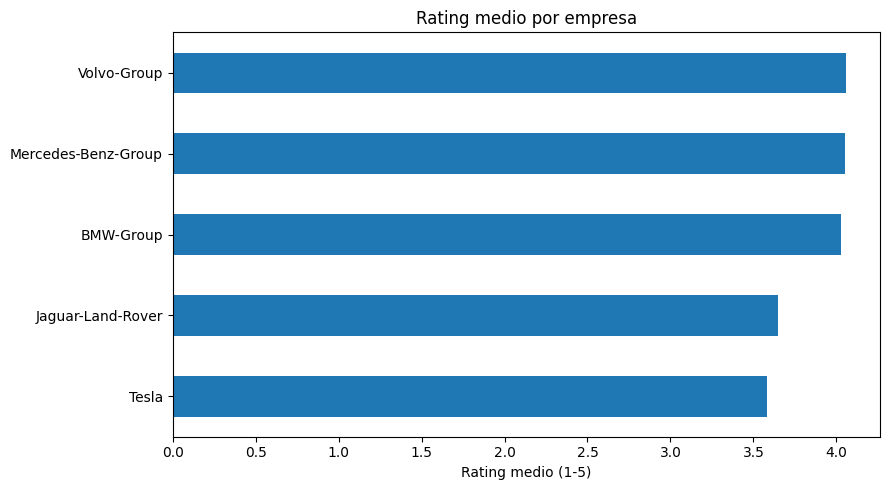

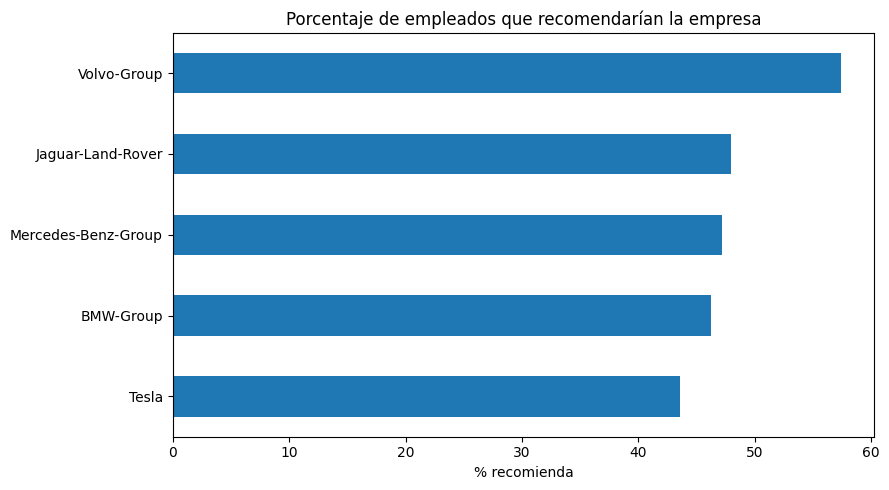

In [7]:
ax = resumen["rating_medio"].sort_values().plot(kind="barh", figsize=(9, 5))
ax.set_title("Rating medio por empresa")
ax.set_xlabel("Rating medio (1-5)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

ax = resumen["pct_recomienda"].sort_values().plot(kind="barh", figsize=(9, 5))
ax.set_title("Porcentaje de empleados que recomendarían la empresa")
ax.set_xlabel("% recomienda")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

situacion,Actual,Antiguo
firm,,
BMW-Group,4.16,3.86
Mercedes-Benz-Group,4.12,3.96
Volvo-Group,4.16,3.85
Jaguar-Land-Rover,3.77,3.41
Tesla,3.80,3.32


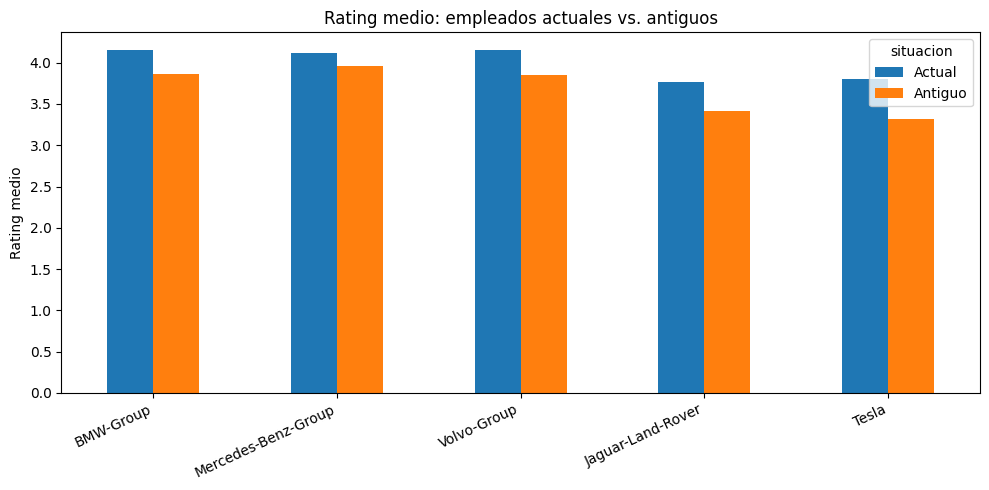

In [8]:
rating_situacion = (
    df_full[df_full["situacion"].isin(["Actual", "Antiguo"])]
    .groupby(["firm", "situacion"])["overall_rating"]
    .mean()
    .unstack()
    .reindex(FIRMS)
    .round(2)
)

display(rating_situacion)

rating_situacion.plot(kind="bar", figsize=(10, 5))
plt.title("Rating medio: empleados actuales vs. antiguos")
plt.ylabel("Rating medio")
plt.xlabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

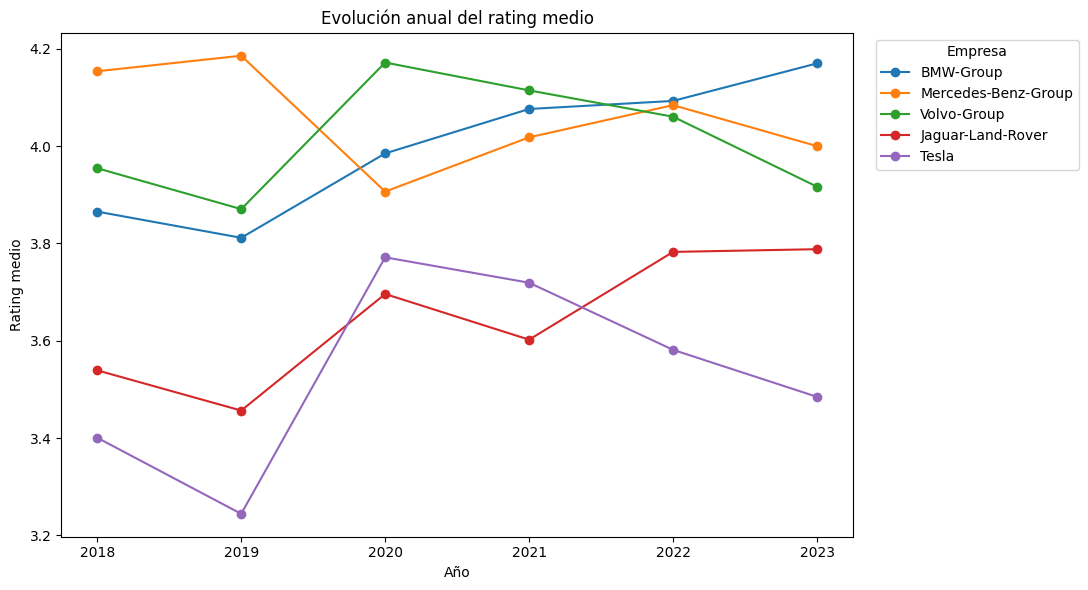

In [9]:
evolucion = (
    df_full.dropna(subset=["anio"])
    .groupby(["anio", "firm"])["overall_rating"]
    .mean()
    .unstack()
    .reindex(columns=FIRMS)
)

ax = evolucion.plot(marker="o", figsize=(11, 6))
ax.set_title("Evolución anual del rating medio")
ax.set_xlabel("Año")
ax.set_ylabel("Rating medio")
plt.legend(title="Empresa", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [10]:
# Ayuda para convertir el EDA en una lectura comparativa de negocio.
metricas = ["rating_medio", "pct_recomienda", "pct_actuales", "pct_antiguos"]
peer_mean = resumen.loc[PEERS, metricas].mean()
target_values = resumen.loc[TARGET, metricas]
comparacion_eda = pd.DataFrame({
    "BMW": target_values,
    "Media_peers": peer_mean,
    "Gap_BMW_menos_peers": target_values - peer_mean,
}).round(2)

display(comparacion_eda)

,BMW,Media_peers,Gap_BMW_menos_peers
rating_medio,4.03,3.84,0.20
pct_recomienda,46.20,49.05,-2.85
pct_actuales,56.60,61.40,-4.80
pct_antiguos,43.40,38.60,4.80


### Lectura de negocio del EDA

#### Posicionamiento general
**BMW presenta un rating medio sólido (4,03)** y superior a la media de los peers, aunque no lidera el grupo. Sin embargo, el **porcentaje que recomienda BMW (46,2 %)** queda ligeramente por debajo de la media de peers. La diferencia entre rating y recomendación indica que una experiencia global razonablemente positiva no implica necesariamente una fuerte intención de recomendar la empresa como lugar de trabajo.

**Acción sugerida:** profundizar en los textos para identificar qué dimensiones concretas limitan la recomendación y cuáles pueden reforzarse en employer branding.

#### Empleados actuales vs. antiguos
En BMW, los empleados actuales puntúan mejor que los antiguos (**4,16 vs. 3,86**). El mismo patrón aparece en los peers, por lo que no se interpreta como causa de salida.

**Acción sugerida:** comparar los temas de los `cons` entre actuales y antiguos, en lugar de utilizar la diferencia de rating como explicación causal de la rotación.

#### Evolución temporal
El rating de BMW muestra una evolución descriptiva favorable durante la ventana analizada. Los años **2018 y 2023 son parciales**, por lo que la tendencia se utiliza como contexto y no como evidencia causal.

**Acción sugerida:** monitorizar la evolución del rating junto con las categorías temáticas prioritarias para comprobar si las posibles mejoras se mantienen en el tiempo.

**Conclusión conjunta del EDA:** BMW parte de una posición general competitiva, pero el análisis textual es necesario para convertir las señales agregadas en palancas concretas de atracción, employer branding y retención.


---
## 3. Muestra equilibrada para NLP

Para sentimiento y BERTopic conviene controlar el volumen. Si Tesla aportara miles de textos y BMW/Mercedes alrededor de mil, el modelo conjunto podría aprender topics dominados por la empresa con más reseñas.

La estrategia es:

1. Exigir que la reseña tenga `pros` y `cons` válidos.
2. Calcular cuántas reseñas válidas tiene la empresa con menos datos.
3. Usar como máximo **900 por empresa**, pero reducir automáticamente ese número si alguna empresa no llega tras la limpieza.
4. Utilizar semilla fija (`SEED=42`) para que la muestra sea reproducible.

Tras comprobar la disponibilidad de textos válidos, todas las empresas seleccionadas permiten utilizar **900 reseñas**, por lo que el NLP trabaja con **4.500 reseñas equilibradas**: 4.500 textos de pros y 4.500 de cons.

Así equilibramos **riqueza de información, comparabilidad y coste computacional**. La muestra no se utiliza en el EDA, donde conservamos todas las reseñas disponibles.

In [11]:
df_nlp_base = df_full[df_full["pros_valido"] & df_full["cons_valido"]].copy()

validas_por_empresa = df_nlp_base["firm"].value_counts().reindex(FIRMS)
if validas_por_empresa.isna().any():
    raise ValueError("Falta alguna de las empresas seleccionadas en el dataset tras la limpieza.")

N_POR_EMPRESA = int(min(MAX_POR_EMPRESA, validas_por_empresa.min()))

print("Reseñas con pros y cons válidos por empresa:")
display(validas_por_empresa.to_frame("disponibles"))
print(f"Muestra equilibrada elegida: {N_POR_EMPRESA} reseñas por empresa")

partes = []
for empresa, grupo in df_nlp_base.groupby("firm"):
    if empresa in FIRMS:
        partes.append(grupo.sample(n=N_POR_EMPRESA, random_state=SEED))

df_nlp = pd.concat(partes, ignore_index=True)
df_nlp = df_nlp.sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Total de reseñas para NLP: {len(df_nlp):,}")
display(df_nlp["firm"].value_counts().reindex(FIRMS).to_frame("n_reseñas"))

Reseñas con pros y cons válidos por empresa:


,disponibles
firm,
BMW-Group,1137
Mercedes-Benz-Group,930
Volvo-Group,1187
Jaguar-Land-Rover,2123
Tesla,5437


Muestra equilibrada elegida: 900 reseñas por empresa
Total de reseñas para NLP: 4,500


,n_reseñas
firm,
BMW-Group,900
Mercedes-Benz-Group,900
Volvo-Group,900
Jaguar-Land-Rover,900
Tesla,900


---
## 4. Sentimiento en pros y cons — control de calidad

`pros` y `cons` ya contienen una orientación semántica implícita. Por eso el sentimiento no se utiliza aquí para “descubrir” si una reseña es buena o mala, sino como **control de calidad** del procesamiento lingüístico.

Usamos `distilbert-base-uncased-finetuned-sst-2-english`, un transformer preentrenado binario (`POSITIVE` / `NEGATIVE`). Esperamos:

- mayoría de `pros` → `POSITIVE`
- mayoría de `cons` → `NEGATIVE`

En la muestra analizada, aproximadamente **el 93 % de los pros** se clasifica como positivo y **el 82 % de los cons** como negativo. La inspección manual muestra que muchas discordancias son coherentes con textos como *“no pros”* o *“no real cons”*: el modelo responde al contenido real de la frase, aunque éste contradiga el nombre del campo.

**Decisión metodológica:** se mantiene DistilBERT sin ajuste adicional porque cumple adecuadamente su función de control de calidad. Se mide también el tiempo de ejecución para documentar el coste computacional en CPU y se utiliza `truncation=True` para evitar errores con textos que superen el límite de 512 tokens.


In [12]:
import torch
from transformers import pipeline

MODEL_SENTIMENT = "distilbert-base-uncased-finetuned-sst-2-english"
DEVICE = 0 if torch.cuda.is_available() else -1
BATCH_SIZE = 32 if torch.cuda.is_available() else 8

print("GPU disponible:", torch.cuda.is_available())
print("Batch size:", BATCH_SIZE)

sentiment_pipe = pipeline(
    "sentiment-analysis",
    model=MODEL_SENTIMENT,
    device=DEVICE,
)

GPU disponible: False
Batch size: 8


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 579.65it/s]


In [13]:
inicio_sentimiento = perf_counter()


def aplicar_sentimiento(textos, nombre_columna):
    resultados = sentiment_pipe(
        textos.tolist(),
        truncation=True,
        max_length=512,
        batch_size=BATCH_SIZE,
    )
    etiquetas = [r["label"] for r in resultados]
    scores = [r["score"] for r in resultados]
    return pd.DataFrame({
        f"sent_{nombre_columna}": etiquetas,
        f"score_{nombre_columna}": scores,
    })


sent_pros = aplicar_sentimiento(df_nlp["pros"], "pros")
sent_cons = aplicar_sentimiento(df_nlp["cons"], "cons")

df_nlp = pd.concat([df_nlp.reset_index(drop=True), sent_pros, sent_cons], axis=1)

tiempo_sentimiento = perf_counter() - inicio_sentimiento
print(f"Sentimiento completado en {tiempo_sentimiento / 60:.2f} min ({tiempo_sentimiento:.1f} s).")

Sentimiento completado en 5.10 min (306.1 s).


In [14]:
qc_sentimiento = df_nlp.groupby("firm").agg(
    pct_pros_positivos=("sent_pros", lambda s: (s == "POSITIVE").mean() * 100),
    pct_cons_negativos=("sent_cons", lambda s: (s == "NEGATIVE").mean() * 100),
).reindex(FIRMS).round(1)

display(qc_sentimiento)

,pct_pros_positivos,pct_cons_negativos
firm,,
BMW-Group,93.0,78.1
Mercedes-Benz-Group,94.3,80.4
Volvo-Group,94.4,81.9
Jaguar-Land-Rover,93.8,85.6
Tesla,89.8,82.4


In [15]:
def muestra_segura(df, n=8):
    if len(df) == 0:
        return df
    return df.sample(n=min(n, len(df)), random_state=SEED)

pros_discordantes = df_nlp[df_nlp["sent_pros"] == "NEGATIVE"]
cons_discordantes = df_nlp[df_nlp["sent_cons"] == "POSITIVE"]

print(f"Pros clasificados como NEGATIVE: {len(pros_discordantes):,}")
display(muestra_segura(pros_discordantes[["firm", "overall_rating", "pros", "sent_pros", "score_pros"]]))

print(f"Cons clasificados como POSITIVE: {len(cons_discordantes):,}")
display(muestra_segura(cons_discordantes[["firm", "overall_rating", "cons", "sent_cons", "score_cons"]]))

Pros clasificados como NEGATIVE: 312


,firm,overall_rating,pros,sent_pros,score_pros
3226,Tesla,1.0,Do I need to say more?,NEGATIVE,0.995865
129,Mercedes-Benz-Group,2.0,no pro's for this company,NEGATIVE,0.999503
784,BMW-Group,5.0,Room to grow into broad field,NEGATIVE,0.846479
809,Tesla,4.0,Lots of room to work on projects,NEGATIVE,0.997288
356,Mercedes-Benz-Group,5.0,Yearly once salary increments very low and my salary low,NEGATIVE,0.998251
843,Volvo-Group,1.0,None that I can think of,NEGATIVE,0.996586
1247,Tesla,4.0,Can make good money here a lot of overtime available,NEGATIVE,0.894350
2587,BMW-Group,1.0,None that were available during my time of employment,NEGATIVE,0.999181


Cons clasificados como POSITIVE: 824


,firm,overall_rating,cons,sent_cons,score_cons
3411,Mercedes-Benz-Group,4.0,Back end technology Large company mentality,POSITIVE,0.991414
934,Jaguar-Land-Rover,5.0,Very complex business in which to try and get things done. The transition to agile is causing some additional challenge right now!,POSITIVE,0.990560
316,Mercedes-Benz-Group,5.0,"the work environment is very good, it's just that I want to live a new experience and learn a lot more",POSITIVE,0.999875
889,BMW-Group,5.0,Long hours that are necessary at times,POSITIVE,0.896956
1516,Mercedes-Benz-Group,5.0,No cons as such now,POSITIVE,0.992919
1805,Jaguar-Land-Rover,5.0,"I was happy to work for JLR, no cons, maybe othes have different opinion",POSITIVE,0.998159
4422,Mercedes-Benz-Group,5.0,"bigger salary, fully remote work",POSITIVE,0.943934
431,Jaguar-Land-Rover,4.0,- Systems / Processes can be very challenging - Experiences with management can be variable,POSITIVE,0.945345


### Lectura del control de calidad

No esperamos un 100 % de coincidencia. La revisión manual de los casos discordantes muestra negaciones, frases ambiguas o respuestas cuyo contenido contradice el nombre del campo; por ejemplo, un `cons` que afirma que no existe ningún aspecto negativo.

Por ello, **no interpretamos cada discordancia como un error de DistilBERT**. El control de calidad se considera satisfactorio y el modelo se mantiene sin ajuste adicional. La inspección de ejemplos se conserva porque ayuda a explicar a RRHH las limitaciones del análisis automático del lenguaje.


---
## 5. Topic modeling con BERTopic — configuración final

Se mantiene la regla fundamental de comparabilidad del enunciado: **un único modelo conjunto para las cinco empresas** en `pros` y otro en `cons`. Entrenar un modelo distinto por empresa produciría topics diferentes y rompería la comparación BMW vs. peers.

### Proceso de calibración

La selección final no se basa en parámetros arbitrarios. Se probaron configuraciones con distinta granularidad y se compararon por número de topics, porcentaje de outliers, concentración del topic dominante e interpretabilidad para RRHH:

| Corpus/configuración | Topics | Outliers | Topic dominante | Lectura |
|---|---:|---:|---:|---|
| PROS · configuración inicial | 5 | 1,7 % | 89,2 % | agrupaba demasiado |
| PROS · alternativa granular | 61 | 39,2 % | 3,6 % | fragmentaba demasiado |
| PROS · candidata A | 51 | 28,3 % | 7,3 % | demasiados microtopics |
| **PROS · candidata B** | **35** | **31,5 %** | **7,8 %** | **mejor compromiso** |
| PROS · candidata C | 35 | 43,0 % | 5,0 % | demasiados outliers |
| CONS · configuración inicial | 29 | 27,6 % | 11,9 % | compacto e interpretable |
| CONS · alternativa granular | 41 | 26,9 % | — | mejora mínima de outliers, más complejidad |

### Decisión final

**PROS → `B_EOM_intermedio`.** Aunque 35 topics constituye un catálogo relativamente fino, la mayoría representan temas reconocibles —equipo, aprendizaje, salario, conciliación, marca, cultura, beneficios, etc.— que después se agrupan manualmente en un número reducido de categorías de RRHH. Se prioriza así la riqueza semántica sin volver a un único topic dominante.

**CONS → configuración compacta.** Los 29 topics son suficientemente interpretables; no compensa generar 12 topics adicionales para reducir solo **0,7 puntos porcentuales** de outliers.

### Tratamiento de outliers

Los textos con topic `-1` se mantienen como **`Sin tema claro`**. No se reasignan automáticamente porque forzar una reseña ambigua a salario, cultura o liderazgo podría generar conclusiones de negocio falsas. La cobertura del clustering se reporta explícitamente.

> Una vez seleccionada la configuración, el objetivo deja de ser “optimizar el clustering” y pasa a **traducir los topics en categorías accionables para RRHH**.


In [16]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer


embedding_model = SentenceTransformer("all-MiniLM-L6-v2")


def crear_modelo_bertopic(
    n_neighbors,
    min_cluster_size,
    min_samples,
    cluster_selection_method,
    min_df=5,
    verbose=False,
):
    """Crea BERTopic con parámetros explícitos y reproducibles."""
    umap_model = UMAP(
        n_neighbors=n_neighbors,
        n_components=5,
        min_dist=0.0,
        metric="cosine",
        random_state=SEED,
    )
    hdbscan_model = HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric="euclidean",
        cluster_selection_method=cluster_selection_method,
        prediction_data=True,
    )
    vectorizer_model = CountVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=min_df,
    )
    return BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        calculate_probabilities=False,
        verbose=verbose,
    )


# Configuración seleccionada en v3 para PROS.
CONFIG_PROS_FINAL = {
    "n_neighbors": 12,
    "min_cluster_size": 25,
    "min_samples": 7,
    "cluster_selection_method": "eom",
    "min_df": 4,
}

# Configuración v1 recuperada para CONS.
CONFIG_CONS_FINAL = {
    "n_neighbors": 15,
    "min_cluster_size": 30,
    "min_samples": 10,
    "cluster_selection_method": "eom",
    "min_df": 5,
}

print("Configuración final PROS — B_EOM_intermedio:")
display(pd.DataFrame([CONFIG_PROS_FINAL], index=["PROS_final"]))

print("\nConfiguración final CONS — v1 recuperada:")
display(pd.DataFrame([CONFIG_CONS_FINAL], index=["CONS_final"]))


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6203.17it/s]


Configuración final PROS — B_EOM_intermedio:


,n_neighbors,min_cluster_size,min_samples,cluster_selection_method,min_df
PROS_final,12,25,7,eom,4



Configuración final CONS — v1 recuperada:


,n_neighbors,min_cluster_size,min_samples,cluster_selection_method,min_df
CONS_final,15,30,10,eom,5


In [17]:
inicio_topics = perf_counter()

textos_pros = df_nlp["pros"].tolist()
textos_cons = df_nlp["cons"].tolist()

# Los embeddings se calculan una vez por corpus.
print("Calculando embeddings para PROS...")
t0 = perf_counter()
embeddings_pros = embedding_model.encode(
    textos_pros,
    show_progress_bar=True,
    batch_size=32,
)
print(f"Embeddings PROS: {perf_counter() - t0:.1f} s")

print("\nCalculando embeddings para CONS...")
t0 = perf_counter()
embeddings_cons = embedding_model.encode(
    textos_cons,
    show_progress_bar=True,
    batch_size=32,
)
print(f"Embeddings CONS: {perf_counter() - t0:.1f} s")

print("\nEntrenando BERTopic final para PROS...")
model_pros = crear_modelo_bertopic(**CONFIG_PROS_FINAL, verbose=False)
t0 = perf_counter()
topics_pros, _ = model_pros.fit_transform(textos_pros, embeddings_pros)
tiempo_pros = perf_counter() - t0
df_nlp["topic_pros"] = np.asarray(topics_pros)
print(f"PROS completado en {tiempo_pros:.1f} s")

print("\nEntrenando BERTopic final para CONS...")
model_cons = crear_modelo_bertopic(**CONFIG_CONS_FINAL, verbose=False)
t0 = perf_counter()
topics_cons, _ = model_cons.fit_transform(textos_cons, embeddings_cons)
tiempo_cons = perf_counter() - t0
df_nlp["topic_cons"] = np.asarray(topics_cons)
print(f"CONS completado en {tiempo_cons:.1f} s")

tiempo_topics = perf_counter() - inicio_topics
print(f"\nBERTopic final completado en {tiempo_topics / 60:.2f} min ({tiempo_topics:.1f} s).")


Calculando embeddings para PROS...


Batches: 100%|██████████| 141/141 [00:18<00:00,  7.75it/s]


Embeddings PROS: 18.3 s

Calculando embeddings para CONS...


Batches: 100%|██████████| 141/141 [00:23<00:00,  5.90it/s]


Embeddings CONS: 23.9 s

Entrenando BERTopic final para PROS...
PROS completado en 31.7 s

Entrenando BERTopic final para CONS...
CONS completado en 9.2 s

BERTopic final completado en 1.38 min (83.1 s).


In [18]:
def diagnostico_topics(topics):
    serie = pd.Series(topics)
    validos = serie[serie != -1]
    conteos = validos.value_counts()

    return {
        "n_topics": int(validos.nunique()),
        "pct_outliers": round((serie == -1).mean() * 100, 1),
        "pct_topic_dominante": round(conteos.iloc[0] / len(serie) * 100, 1) if len(conteos) else np.nan,
        "pct_textos_top5": round(conteos.head(5).sum() / len(serie) * 100, 1) if len(conteos) else np.nan,
        "topics_menor_1pct": int((conteos / len(serie) < 0.01).sum()) if len(conteos) else 0,
    }


diag_final = pd.DataFrame(
    {
        "PROS_final_B": diagnostico_topics(df_nlp["topic_pros"]),
        "CONS_final_v1": diagnostico_topics(df_nlp["topic_cons"]),
    }
).T

print("Diagnóstico de la configuración final:")
display(diag_final)

# Historial observado en ejecuciones previas. Se conserva para documentar
# por qué se eligió la configuración final; no se reentrenan esos modelos.
historial_pros = pd.DataFrame(
    {
        "n_topics": [5, 61, 51, 35, 35],
        "pct_outliers": [1.7, 39.2, 28.3, 31.5, 43.0],
        "pct_topic_dominante": [89.2, 3.6, 7.3, 7.8, 5.0],
    },
    index=["v1_PROS", "v2_PROS", "A_EOM_local", "B_EOM_intermedio", "C_LEAF_moderado"],
)
print("\nHistorial de calibración PROS:")
display(historial_pros)

# Cobertura del clustering por empresa antes del etiquetado manual.
cobertura_topics = df_nlp.groupby("firm").agg(
    pct_pros_con_topic=("topic_pros", lambda s: (s != -1).mean() * 100),
    pct_cons_con_topic=("topic_cons", lambda s: (s != -1).mean() * 100),
).reindex(FIRMS).round(1)

print("\nCobertura del clustering por empresa:")
display(cobertura_topics)


Diagnóstico de la configuración final:


,n_topics,pct_outliers,pct_topic_dominante,pct_textos_top5,topics_menor_1pct
PROS_final_B,35.0,31.5,7.8,28.6,13.0
CONS_final_v1,29.0,27.6,11.9,34.8,5.0



Historial de calibración PROS:


,n_topics,pct_outliers,pct_topic_dominante
v1_PROS,5,1.7,89.2
v2_PROS,61,39.2,3.6
A_EOM_local,51,28.3,7.3
B_EOM_intermedio,35,31.5,7.8
C_LEAF_moderado,35,43.0,5.0



Cobertura del clustering por empresa:


,pct_pros_con_topic,pct_cons_con_topic
firm,,
BMW-Group,72.2,73.8
Mercedes-Benz-Group,71.3,75.9
Volvo-Group,63.8,74.7
Jaguar-Land-Rover,64.7,64.7
Tesla,70.4,73.1


---
## 6. Revisión manual y categorías de negocio

BERTopic produce **topics estadísticos**, pero RRHH necesita **categorías interpretables**. Por eso no utilizamos directamente los 35 topics de `pros` y 29 de `cons` como si fueran 64 palancas distintas.

La revisión manual del catálogo final muestra que muchos topics son variantes del mismo concepto:

- `pay`, `salary`, `bonus`, `stock options`, `health insurance` → **Compensación y beneficios**;
- `work-life balance`, `flexible working`, `long hours`, `shifts`, `stress` → **Conciliación y carga de trabajo**;
- `learning`, `training`, `growth`, `promotion`, `career progression` → **Carrera, aprendizaje y desarrollo**.

La agrupación se hace **manualmente**, revisando palabras clave y ejemplos representativos. Esta decisión es deliberada: una fusión automática podría juntar temas parecidos lingüísticamente pero distintos para RRHH.

### Marco de categorías utilizado

Buscamos un conjunto reducido y común para poder comparar `pros` y `cons`:

- Compensación y beneficios
- Conciliación y carga de trabajo
- Cultura y ambiente
- Equipo y liderazgo
- Carrera, aprendizaje y desarrollo
- Procesos y organización
- Marca, producto y propósito
- Innovación y entorno dinámico
- Condiciones del puesto y operativa
- Inclusión y entorno internacional

Además se conservan tres estados de control que **no se interpretan como palancas de RRHH**:

- `Sin tema claro` → outlier de BERTopic;
- `Sin problema declarado` → textos de `cons` del tipo “no tengo nada negativo que decir”;
- `Comentario genérico / sin contenido accionable` → topic demasiado genérico para sostener una recomendación.

Estos estados se reportan para no ocultar información, pero se excluyen de los porcentajes de categorías accionables.


In [19]:
def catalogo_topics(modelo, max_topics=None):
    info = modelo.get_topic_info().copy()
    if max_topics is not None:
        info = info.head(max_topics)

    filas = []

    for _, row in info.iterrows():
        topic = int(row["Topic"])

        if topic == -1:
            palabras = "OUTLIER / sin tema claro"
            ejemplos = []
        else:
            palabras = ", ".join([p for p, _ in modelo.get_topic(topic)[:8]])
            try:
                ejemplos = modelo.get_representative_docs(topic)[:3]
            except Exception:
                ejemplos = []

        filas.append({
            "topic": topic,
            "count": int(row["Count"]),
            "nombre_modelo": row.get("Name", ""),
            "palabras_clave": palabras,
            "ejemplo_1": ejemplos[0] if len(ejemplos) > 0 else "",
            "ejemplo_2": ejemplos[1] if len(ejemplos) > 1 else "",
            "ejemplo_3": ejemplos[2] if len(ejemplos) > 2 else "",
        })

    return pd.DataFrame(filas)


print("=" * 90)
print("CATÁLOGO COMPLETO PROS — B_EOM_intermedio")
print("=" * 90)
catalogo_pros = catalogo_topics(model_pros, max_topics=None)
display(catalogo_pros)

print("\n" + "=" * 90)
print("CATÁLOGO COMPLETO CONS — configuración v1 recuperada")
print("=" * 90)
catalogo_cons = catalogo_topics(model_cons, max_topics=None)
display(catalogo_cons)


CATÁLOGO COMPLETO PROS — B_EOM_intermedio


,topic,count,nombre_modelo,palabras_clave,ejemplo_1,ejemplo_2,ejemplo_3
0,-1,1418,-1_good_work_life_work life,OUTLIER / sin tema claro,,,
1,0,350,0_place_place work_great place_good place,"place, place work, great place, good place, nice, work good, work, good good",Rhys was a great place to work,great place to work in,Great place to work with
2,1,347,1_environment_people_friendly_work environment,"environment, people, friendly, work environment, nice, working environment, colleagues, environment work",Nice people and nice working environment.,"Well, the work environment was very professional and the people are very nice.",Nice working environment Good people
3,2,247,2_cars_car_automotive_company car,"cars, car, automotive, company car, drive, scheme, industry, brand",Cheaper Car Parts for personal cars,"you get a paycheck, if you can sell cars",Great cars to work with and on.
4,3,175,3_good company_company_company work_great company,"good company, company, company work, great company, company good, company great, good, great",Good company to work with,Very good company to work,A good company to work for.
5,4,169,4_flexible_flexible working_working_hours,"flexible, flexible working, working, hours, time, working hours, home, schedule","flexible working hours, luxus brand","Good rewards, flexible working hours","good collogues, flexible working hours"
6,5,162,5_team_great team_teams_team good,"team, great team, teams, team good, good team, team great, great, team members",Felt integrated into the team,Felt easily integrated into the team.,Was a good laugh with some of the team
7,6,141,6_brand_products_product_great products,"brand, products, product, great products, good brand, great brand, great, strong","Great brand, Great products, good opportunies to move around, good canteen",- Strong portfolio of products - Amazing brand,"Brand, Salary, People, Salary, Brand"
8,7,111,7_learning_learn_training_experience,"learning, learn, training, experience, lot, opportunities, education, opportunity",Learning opportunities and training and development.,Lot's of learning experience and plenty of growth,Great learning experience if you are new to the industry
9,8,99,8_pay_money_good pay_pay good,"pay, money, good pay, pay good, money good, good money, good, job",Good pay. That’s about it,Good pay and good work,Money is worthwhile good pay



CATÁLOGO COMPLETO CONS — configuración v1 recuperada


,topic,count,nombre_modelo,palabras_clave,ejemplo_1,ejemplo_2,ejemplo_3
0,-1,1241,-1_management_people_managers_lack,OUTLIER / sin tema claro,,,
1,0,534,0_hours_long_long hours_work,"hours, long, long hours, work, overtime, time, workload, hard",Hours We’re long hours in,Very long hours with continuous work.,Long hours yo work there
2,1,347,1_think_say_mention_bad,"think, say, mention, bad, really, negative, good, great",Nothing that I can think of,Can't really think of one,Cant really think of any
3,2,321,2_salary_pay_low_benefits,"salary, pay, low, benefits, low salary, market, compared, better",Salary is less and not satisfied,Salary not upto the mark,Salary is not so much.
4,3,196,3_cons_company_place work_place,"cons, company, place work, place, great, good, good company, working",No Cons great place to work,"Not many cons, was a great place to work.","No cons, great place to work"
5,4,166,4_management_bad_bad management_senior,"management, bad, bad management, senior, senior management, managers, manager, like","Bad managememt, partial management, No approeciation",Top management can be unrealistic,Management seems to be confused
6,5,160,5_balance_life balance_life_work life,"balance, life balance, life, work life, work, covid, home, remote",Work life balance is not at all there.,Less work life balance at volvo,Work life balance is not factored.
7,6,139,6_cons_think_say_moment,"cons, think, say, moment, did, don, really, report",No Cons only Pros are there.,No cons that i faced yet.,There are no cons yet.
8,7,137,7_slow_processes_process_processes slow,"slow, processes, process, processes slow, product, change, big, rigid",Some processes might be slow,processes are a bit slow sometimes,- often slow due to a lot of processes
9,8,124,8_parking_location_far_food,"parking, location, far, food, city, commute, office, travel","bad location, far from a train station",No work life/balance Commute at GFTX is horrendous with the shuttle system. Need to wait in parking lot for 20 minutes to ride shuttle bus to office location.,The location was far from city


### 6.1 Etiquetado manual de los topics adicionales

Al revisar el catálogo completo del modelo final de `pros` se identificaron seis topics adicionales (`29–34`) que requerían una asignación explícita. La decisión se basa en **palabras clave y ejemplos representativos**, no únicamente en el nombre automático de BERTopic.

| Topic | Señal semántica principal | Categoría de negocio |
|---:|---|---|
| 29 | productos, tecnología, desarrollo, producto interesante | **Innovación y entorno dinámico** |
| 30 | proyectos, ideas, tecnologías, proyectos interesantes | **Innovación y entorno dinámico** |
| 31 | cultura de grupo, clima, inclusión | **Cultura y ambiente** |
| 32 | salario, buen salario, ambiente | **Compensación y beneficios** |
| 33 | cultura de empresa / corporate culture | **Cultura y ambiente** |
| 34 | work-life balance | **Conciliación y carga de trabajo** |

Con estas asignaciones queda completado el mapeo de **todos los topics de `pros` y `cons`** del modelo seleccionado.

### Por qué agrupamos topics

BERTopic detecta patrones semánticos finos, pero RRHH necesita un conjunto reducido de palancas comparables. Por eso distintos topics sobre `salary`, `bonus`, `stock options` o `health insurance`, por ejemplo, se integran en **Compensación y beneficios**.

La agrupación manual no pretende “corregir” al modelo: traduce su salida técnica a una taxonomía de negocio común para `pros` y `cons`. Se mantienen aparte los outliers y los comentarios sin contenido accionable para no forzar conclusiones dudosas.


In [20]:
# Mapeo manual final basado en palabras clave y ejemplos representativos.
# PROS: topics 0-28 revisados en v3 y topics 29-34 revisados con el catálogo completo de v4.
MAP_PROS = {
    0: "Cultura y ambiente",
    1: "Cultura y ambiente",
    2: "Marca, producto y propósito",
    3: "Marca, producto y propósito",
    4: "Conciliación y carga de trabajo",
    5: "Equipo y liderazgo",
    6: "Marca, producto y propósito",
    7: "Carrera, aprendizaje y desarrollo",
    8: "Compensación y beneficios",
    9: "Compensación y beneficios",
    10: "Marca, producto y propósito",
    11: "Cultura y ambiente",
    12: "Compensación y beneficios",
    13: "Conciliación y carga de trabajo",
    14: "Marca, producto y propósito",
    15: "Conciliación y carga de trabajo",
    16: "Compensación y beneficios",
    17: "Equipo y liderazgo",
    18: "Compensación y beneficios",
    19: "Marca, producto y propósito",
    20: "Cultura y ambiente",
    21: "Comentario genérico / sin contenido accionable",
    22: "Innovación y entorno dinámico",
    23: "Carrera, aprendizaje y desarrollo",
    24: "Cultura y ambiente",
    25: "Carrera, aprendizaje y desarrollo",
    26: "Conciliación y carga de trabajo",
    27: "Compensación y beneficios",
    28: "Cultura y ambiente",
    29: "Innovación y entorno dinámico",
    30: "Innovación y entorno dinámico",
    31: "Cultura y ambiente",
    32: "Compensación y beneficios",
    33: "Cultura y ambiente",
    34: "Conciliación y carga de trabajo",
}

# CONS: mapeo completo tras revisar los 29 topics de la configuración v1.
MAP_CONS = {
    0: "Conciliación y carga de trabajo",
    1: "Sin problema declarado",
    2: "Compensación y beneficios",
    3: "Sin problema declarado",
    4: "Equipo y liderazgo",
    5: "Conciliación y carga de trabajo",
    6: "Sin problema declarado",
    7: "Procesos y organización",
    8: "Condiciones del puesto y operativa",
    9: "Cultura y ambiente",
    10: "Marca, producto y propósito",
    11: "Carrera, aprendizaje y desarrollo",
    12: "Conciliación y carga de trabajo",
    13: "Equipo y liderazgo",
    14: "Carrera, aprendizaje y desarrollo",
    15: "Procesos y organización",
    16: "Condiciones del puesto y operativa",
    17: "Cultura y ambiente",
    18: "Carrera, aprendizaje y desarrollo",
    19: "Carrera, aprendizaje y desarrollo",
    20: "Marca, producto y propósito",
    21: "Procesos y organización",
    22: "Procesos y organización",
    23: "Conciliación y carga de trabajo",
    24: "Equipo y liderazgo",
    25: "Cultura y ambiente",
    26: "Inclusión y entorno internacional",
    27: "Procesos y organización",
    28: "Equipo y liderazgo",
}


def asignar_categoria(topic, mapping):
    if topic == -1:
        return "Sin tema claro"
    return mapping.get(int(topic), f"REVISAR_topic_{int(topic)}")


df_nlp["categoria_pros"] = df_nlp["topic_pros"].apply(
    lambda t: asignar_categoria(t, MAP_PROS)
)
df_nlp["categoria_cons"] = df_nlp["topic_cons"].apply(
    lambda t: asignar_categoria(t, MAP_CONS)
)

CATEGORIAS_EXCLUIR_ANALISIS = {
    "Sin tema claro",
    "Sin problema declarado",
    "Comentario genérico / sin contenido accionable",
}

pendientes_pros = sorted(
    df_nlp.loc[
        df_nlp["categoria_pros"].str.startswith("REVISAR"),
        "topic_pros",
    ].unique()
)
pendientes_cons = sorted(
    df_nlp.loc[
        df_nlp["categoria_cons"].str.startswith("REVISAR"),
        "topic_cons",
    ].unique()
)

print("Topics PROS pendientes de revisión:", pendientes_pros)
print("Topics CONS pendientes de revisión:", pendientes_cons)

if pendientes_pros or pendientes_cons:
    print("\n⚠️ Quedan topics sin categorizar. Revisa el catálogo antes de interpretar balances.")
    if pendientes_pros:
        display(catalogo_pros[catalogo_pros["topic"].isin(pendientes_pros)])
    if pendientes_cons:
        display(catalogo_cons[catalogo_cons["topic"].isin(pendientes_cons)])
else:
    print("\n✅ Etiquetado completo: todos los topics del modelo final tienen una categoría o estado de control.")

# Control de cobertura del etiquetado.
def pct_accionable(serie):
    mask = (
        ~serie.isin(CATEGORIAS_EXCLUIR_ANALISIS)
        & ~serie.str.startswith("REVISAR")
    )
    return mask.mean() * 100

cobertura_etiquetado = df_nlp.groupby("firm").agg(
    pct_pros_accionables=("categoria_pros", pct_accionable),
    pct_cons_accionables=("categoria_cons", pct_accionable),
).reindex(FIRMS).round(1)

print("\nCobertura de categorías accionables por empresa:")
display(cobertura_etiquetado)


Topics PROS pendientes de revisión: []
Topics CONS pendientes de revisión: []

✅ Etiquetado completo: todos los topics del modelo final tienen una categoría o estado de control.

Cobertura de categorías accionables por empresa:


,pct_pros_accionables,pct_cons_accionables
firm,,
BMW-Group,71.3,54.3
Mercedes-Benz-Group,70.2,58.8
Volvo-Group,63.0,54.2
Jaguar-Land-Rover,63.7,55.6
Tesla,69.2,63.4


---
## 7. Comparación con peers: peso, balance neto y gap

Con el etiquetado completo comparamos BMW con la media de sus cuatro peers usando una taxonomía común.

Para cada empresa calculamos:

**Balance neto por categoría = % en pros − % en cons**

y después:

**Gap BMW = balance neto de BMW − balance neto medio de peers**

### Criterio de interpretación

El signo del gap **no basta por sí solo** para llamar a una categoría fortaleza o debilidad. Hay que mirar simultáneamente el balance de BMW:

- **Fortaleza real** → balance BMW positivo **y** gap positivo.
- **Ventaja relativa, pero balance aún negativo** → BMW está mejor que los peers, aunque en BMW siguen pesando más los `cons` que los `pros`.
- **Debilidad relativa** → balance BMW negativo **y** gap negativo.
- **Oportunidad de employer branding** → balance BMW positivo pero gap negativo; BMW recibe menciones favorables, aunque los peers destacan todavía más en esa dimensión.

Esta distinción evita, por ejemplo, presentar como “fortaleza” una categoría problemática solo porque BMW está **menos mal que el mercado**.

### Denominador utilizado

Los porcentajes se calculan sobre textos con una **categoría accionable** asignada. Se excluyen `Sin tema claro`, `Sin problema declarado` y comentarios genéricos sin contenido suficiente.

La cobertura del etiquetado se muestra previamente para que esta exclusión sea transparente. El balance y el gap son medidas **relativas y descriptivas**: orientan prioridades, pero no demuestran causalidad.


In [21]:
def analisis_categorias(df):
    pendientes = (
        df["categoria_pros"].str.startswith("REVISAR").any()
        or df["categoria_cons"].str.startswith("REVISAR").any()
    )
    if pendientes:
        print("⏸ Balance neto pendiente: quedan topics por revisar.")
        return None

    pros_ok = df[~df["categoria_pros"].isin(CATEGORIAS_EXCLUIR_ANALISIS)].copy()
    cons_ok = df[~df["categoria_cons"].isin(CATEGORIAS_EXCLUIR_ANALISIS)].copy()

    pct_pros = (
        pros_ok.groupby("firm")["categoria_pros"]
        .value_counts(normalize=True)
        .mul(100)
        .rename("pct_pros")
        .reset_index()
        .rename(columns={"categoria_pros": "categoria"})
    )
    pct_cons = (
        cons_ok.groupby("firm")["categoria_cons"]
        .value_counts(normalize=True)
        .mul(100)
        .rename("pct_cons")
        .reset_index()
        .rename(columns={"categoria_cons": "categoria"})
    )

    tabla = pct_pros.merge(
        pct_cons, on=["firm", "categoria"], how="outer"
    ).fillna(0)
    tabla["balance_neto"] = tabla["pct_pros"] - tabla["pct_cons"]

    target = tabla[tabla["firm"] == TARGET].set_index("categoria")
    peers = (
        tabla[tabla["firm"].isin(PEERS)]
        .groupby("categoria")[["pct_pros", "pct_cons", "balance_neto"]]
        .mean()
    )

    comparacion = target[["pct_pros", "pct_cons", "balance_neto"]].join(
        peers,
        how="outer",
        lsuffix="_BMW",
        rsuffix="_Peers",
    ).fillna(0)

    comparacion["gap_balance_BMW_menos_peers"] = (
        comparacion["balance_neto_BMW"] - comparacion["balance_neto_Peers"]
    )

    # Añadimos número de textos BMW para no interpretar porcentajes
    # pequeños sin conocer el volumen que hay detrás.
    n_pros_bmw = (
        pros_ok[pros_ok["firm"] == TARGET]["categoria_pros"]
        .value_counts()
    )
    n_cons_bmw = (
        cons_ok[cons_ok["firm"] == TARGET]["categoria_cons"]
        .value_counts()
    )
    comparacion["n_pros_BMW"] = n_pros_bmw
    comparacion["n_cons_BMW"] = n_cons_bmw
    comparacion[["n_pros_BMW", "n_cons_BMW"]] = (
        comparacion[["n_pros_BMW", "n_cons_BMW"]].fillna(0).astype(int)
    )

    def interpretar_categoria(fila):
        gap = fila["gap_balance_BMW_menos_peers"]
        balance = fila["balance_neto_BMW"]

        if balance > 0 and gap > 0:
            return "Fortaleza real"
        if balance <= 0 and gap > 0:
            return "Ventaja relativa, balance BMW aún negativo"
        if balance < 0 and gap < 0:
            return "Debilidad relativa"
        if balance >= 0 and gap < 0:
            return "Oportunidad de employer branding"
        return "Posición similar a peers"

    comparacion["interpretacion"] = comparacion.apply(
        interpretar_categoria, axis=1
    )

    return tabla, comparacion.sort_values("gap_balance_BMW_menos_peers")


resultado_categorias = analisis_categorias(df_nlp)

if resultado_categorias is not None:
    tabla_categorias, comparacion_bmw = resultado_categorias

    columnas_mostrar = [
        "n_pros_BMW", "n_cons_BMW",
        "pct_pros_BMW", "pct_cons_BMW",
        "balance_neto_BMW", "balance_neto_Peers",
        "gap_balance_BMW_menos_peers", "interpretacion",
    ]

    print("BMW vs. media de peers — balance neto e interpretación:")
    display(comparacion_bmw[columnas_mostrar].round(2))

    debilidades_reales = comparacion_bmw[
        comparacion_bmw["interpretacion"] == "Debilidad relativa"
    ].sort_values("gap_balance_BMW_menos_peers")

    fortalezas_reales = comparacion_bmw[
        comparacion_bmw["interpretacion"] == "Fortaleza real"
    ].sort_values("gap_balance_BMW_menos_peers", ascending=False)

    ventajas_relativas = comparacion_bmw[
        comparacion_bmw["interpretacion"]
        == "Ventaja relativa, balance BMW aún negativo"
    ].sort_values("gap_balance_BMW_menos_peers", ascending=False)

    oportunidades_branding = comparacion_bmw[
        comparacion_bmw["interpretacion"]
        == "Oportunidad de employer branding"
    ].sort_values("gap_balance_BMW_menos_peers")

    print("\nDebilidades relativas reales de BMW:")
    display(debilidades_reales[columnas_mostrar].round(2))

    print("\nFortalezas reales de BMW:")
    display(fortalezas_reales[columnas_mostrar].round(2))

    print("\nBMW mejor que peers, pero con balance aún negativo:")
    display(ventajas_relativas[columnas_mostrar].round(2))

    print("\nOportunidades positivas donde los peers destacan todavía más:")
    display(oportunidades_branding[columnas_mostrar].round(2))


BMW vs. media de peers — balance neto e interpretación:


,n_pros_BMW,n_cons_BMW,pct_pros_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,gap_balance_BMW_menos_peers,interpretacion
categoria,,,,,,,,
Conciliación y carga de trabajo,55,172,8.57,35.17,-26.61,-16.86,-9.75,Debilidad relativa
Compensación y beneficios,77,62,11.99,12.68,-0.69,2.29,-2.98,Debilidad relativa
Inclusión y entorno internacional,0,17,0.00,3.48,-3.48,-1.15,-2.33,Debilidad relativa
Innovación y entorno dinámico,15,0,2.34,0.00,2.34,4.07,-1.73,Oportunidad de employer branding
Condiciones del puesto y operativa,0,38,0.00,7.77,-7.77,-6.98,-0.79,Debilidad relativa
"Carrera, aprendizaje y desarrollo",37,44,5.76,9.00,-3.23,-3.67,0.44,"Ventaja relativa, balance BMW aún negativo"
Cultura y ambiente,203,31,31.62,6.34,25.28,23.87,1.41,Fortaleza real
Procesos y organización,0,49,0.00,10.02,-10.02,-13.92,3.90,"Ventaja relativa, balance BMW aún negativo"
Equipo y liderazgo,51,48,7.94,9.82,-1.87,-5.92,4.05,"Ventaja relativa, balance BMW aún negativo"



Debilidades relativas reales de BMW:


,n_pros_BMW,n_cons_BMW,pct_pros_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,gap_balance_BMW_menos_peers,interpretacion
categoria,,,,,,,,
Conciliación y carga de trabajo,55,172,8.57,35.17,-26.61,-16.86,-9.75,Debilidad relativa
Compensación y beneficios,77,62,11.99,12.68,-0.69,2.29,-2.98,Debilidad relativa
Inclusión y entorno internacional,0,17,0.00,3.48,-3.48,-1.15,-2.33,Debilidad relativa
Condiciones del puesto y operativa,0,38,0.00,7.77,-7.77,-6.98,-0.79,Debilidad relativa



Fortalezas reales de BMW:


,n_pros_BMW,n_cons_BMW,pct_pros_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,gap_balance_BMW_menos_peers,interpretacion
categoria,,,,,,,,
"Marca, producto y propósito",204,28,31.78,5.73,26.05,18.27,7.78,Fortaleza real
Cultura y ambiente,203,31,31.62,6.34,25.28,23.87,1.41,Fortaleza real



BMW mejor que peers, pero con balance aún negativo:


,n_pros_BMW,n_cons_BMW,pct_pros_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,gap_balance_BMW_menos_peers,interpretacion
categoria,,,,,,,,
Equipo y liderazgo,51,48,7.94,9.82,-1.87,-5.92,4.05,"Ventaja relativa, balance BMW aún negativo"
Procesos y organización,0,49,0.00,10.02,-10.02,-13.92,3.90,"Ventaja relativa, balance BMW aún negativo"
"Carrera, aprendizaje y desarrollo",37,44,5.76,9.00,-3.23,-3.67,0.44,"Ventaja relativa, balance BMW aún negativo"



Oportunidades positivas donde los peers destacan todavía más:


,n_pros_BMW,n_cons_BMW,pct_pros_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,gap_balance_BMW_menos_peers,interpretacion
categoria,,,,,,,,
Innovación y entorno dinámico,15,0,2.34,0.0,2.34,4.07,-1.73,Oportunidad de employer branding


### 7.1 Lectura de negocio del balance final

El balance final permite distinguir entre **estar mejor que los peers** y disponer de una **fortaleza real**:

- **Marca, producto y propósito** y **Cultura y ambiente** combinan balance positivo en BMW y gap positivo: son fortalezas defendibles para employer branding.
- **Equipo y liderazgo**, **Procesos y organización** y **Carrera y desarrollo** presentan un gap favorable, pero su balance BMW sigue siendo negativo. BMW está relativamente mejor que el mercado, aunque no conviene presentarlas como fortalezas absolutas.
- **Innovación y entorno dinámico** tiene balance positivo en BMW y 0 % de `cons`, pero los peers obtienen un balance todavía mayor. Se interpreta como **oportunidad para reforzar la propuesta de valor**, no como un problema.
- Las debilidades que pasan a priorización son aquellas con **balance BMW negativo y gap negativo**.

**Cautela con Inclusión y entorno internacional.** En BMW aparecen **17 `cons` accionables** en esta categoría y no emerge un topic positivo suficientemente específico que funcione como contraparte directa; algunas menciones favorables relacionadas con inclusión quedan mezcladas dentro de **Cultura y ambiente**. Por su bajo volumen y esta asimetría temática, el balance se interpreta como **señal secundaria a investigar**, no como prioridad concluyente.

Esta separación hace que las conclusiones sean más comprensibles para RRHH y evita recomendaciones contradictorias.


### 7.2 Contraste con `overall_rating` y `recommend`

El enunciado pide contrastar las conclusiones del texto con variables estructuradas. Si una categoría negativa es realmente relevante, es razonable comprobar si las reseñas asociadas muestran **menor rating y/o menor recomendación**.

Este contraste funciona como una validación descriptiva adicional. **No demuestra causalidad**: una categoría puede coexistir con una mala valoración sin ser necesariamente su causa.


In [22]:
if not df_nlp["categoria_cons"].str.startswith("REVISAR").any():
    bmw_cons = df_nlp[
        (df_nlp["firm"] == TARGET)
        & (~df_nlp["categoria_cons"].isin(CATEGORIAS_EXCLUIR_ANALISIS))
    ].copy()

    contraste = bmw_cons.groupby("categoria_cons").agg(
        n=("firm", "size"),
        rating_medio=("overall_rating", "mean"),
        pct_recomienda=("recomienda_si", lambda s: s.mean() * 100),
    ).sort_values("n", ascending=False)

    print("BMW — contraste de categorías negativas con rating y recomendación:")
    display(contraste.round(2))
else:
    print("⏸ Contraste pendiente hasta completar MAP_CONS.")


BMW — contraste de categorías negativas con rating y recomendación:


,n,rating_medio,pct_recomienda
categoria_cons,,,
Conciliación y carga de trabajo,172,4.07,48.26
Compensación y beneficios,62,3.95,50.00
Procesos y organización,49,4.29,55.10
Equipo y liderazgo,48,3.08,27.08
"Carrera, aprendizaje y desarrollo",44,3.86,50.00
Condiciones del puesto y operativa,38,4.00,57.89
Cultura y ambiente,31,3.68,54.84
"Marca, producto y propósito",28,4.46,50.00
Inclusión y entorno internacional,17,3.88,17.65


---
## 8. BMW: empleados actuales vs. antiguos

Los antiguos empleados tienden a puntuar peor en muchas empresas, por lo que no utilizamos esa diferencia de sentimiento como prueba de una causa de salida. La comparación útil se centra en **qué temas negativos cambian de peso**.

El análisis muestra dos señales relevantes:

- **Equipo y liderazgo** y **Conciliación y carga de trabajo** aparecen con más peso entre antiguos que entre actuales de BMW.
- Al comparar antiguos de BMW con antiguos de los peers, **Conciliación y carga de trabajo** presenta una desventaja relativa para BMW; en cambio, liderazgo puede ser una señal interna de salida sin constituir una debilidad frente al mercado.

Por tanto, distinguimos entre:
- un problema que gana presencia entre quienes ya se han marchado;
- y un problema en el que BMW está además peor que sus competidores.

Esta distinción evita convertir cualquier diferencia entre actuales y antiguos en una supuesta causa de rotación.


In [23]:
if not df_nlp["categoria_cons"].str.startswith("REVISAR").any():
    cons_cat = df_nlp[
        ~df_nlp["categoria_cons"].isin(CATEGORIAS_EXCLUIR_ANALISIS)
    ].copy()

    bmw_estado = (
        cons_cat[
            (cons_cat["firm"] == TARGET)
            & cons_cat["situacion"].isin(["Actual", "Antiguo"])
        ]
        .groupby("situacion")["categoria_cons"]
        .value_counts(normalize=True)
        .mul(100)
        .rename("pct")
        .reset_index()
        .pivot(index="categoria_cons", columns="situacion", values="pct")
        .fillna(0)
    )

    bmw_estado["gap_antiguos_menos_actuales"] = (
        bmw_estado.get("Antiguo", 0) - bmw_estado.get("Actual", 0)
    )
    print("BMW — categorías en CONS: antiguos vs. actuales")
    display(
        bmw_estado
        .sort_values("gap_antiguos_menos_actuales", ascending=False)
        .round(2)
    )

    antiguos = cons_cat[cons_cat["situacion"] == "Antiguo"].copy()
    pct_antiguos = (
        antiguos.groupby("firm")["categoria_cons"]
        .value_counts(normalize=True)
        .mul(100)
        .rename("pct")
        .reset_index()
    )

    bmw_ant = (
        pct_antiguos[pct_antiguos["firm"] == TARGET]
        .set_index("categoria_cons")["pct"]
    )
    peers_ant = (
        pct_antiguos[pct_antiguos["firm"].isin(PEERS)]
        .groupby("categoria_cons")["pct"]
        .mean()
    )

    salida = pd.concat(
        [bmw_ant.rename("BMW"), peers_ant.rename("Media_peers")],
        axis=1,
    ).fillna(0)
    salida["gap_BMW_menos_peers"] = salida["BMW"] - salida["Media_peers"]

    print("BMW vs peers — CONS de antiguos empleados")
    display(
        salida
        .sort_values("gap_BMW_menos_peers", ascending=False)
        .round(2)
    )
else:
    print("⏸ Análisis actuales vs. antiguos pendiente hasta completar MAP_CONS.")


BMW — categorías en CONS: antiguos vs. actuales


situacion,Actual,Antiguo,gap_antiguos_menos_actuales
categoria_cons,,,
Equipo y liderazgo,7.97,12.21,4.24
Conciliación y carga de trabajo,33.70,37.09,3.39
Procesos y organización,9.42,10.80,1.38
"Carrera, aprendizaje y desarrollo",9.06,8.92,-0.14
Cultura y ambiente,6.52,6.10,-0.42
"Marca, producto y propósito",6.16,5.16,-1.00
Inclusión y entorno internacional,3.99,2.82,-1.17
Condiciones del puesto y operativa,8.70,6.57,-2.12
Compensación y beneficios,14.49,10.33,-4.16


BMW vs peers — CONS de antiguos empleados


,BMW,Media_peers,gap_BMW_menos_peers
categoria_cons,,,
Conciliación y carga de trabajo,37.09,32.44,4.65
Compensación y beneficios,10.33,8.32,2.00
Inclusión y entorno internacional,2.82,3.18,-0.36
"Marca, producto y propósito",5.16,5.80,-0.63
Condiciones del puesto y operativa,6.57,7.79,-1.22
Procesos y organización,10.80,12.02,-1.22
"Carrera, aprendizaje y desarrollo",8.92,10.23,-1.31
Cultura y ambiente,6.10,8.08,-1.98
Equipo y liderazgo,12.21,15.98,-3.77


---
## 9. Matriz de priorización para RRHH

La matriz utiliza únicamente **debilidades relativas reales**: categorías con balance negativo en BMW y además peor balance que la media de peers.

Combinamos dos dimensiones:

- **Peso en los cons de BMW** → frecuencia del problema entre los textos negativos accionables.
- **Desventaja frente a peers** → cuánto peor es el balance de BMW respecto al mercado.

Así evitamos incluir como “problema” una categoría positiva como **Innovación y entorno dinámico**, que en BMW no registra `cons` accionables y simplemente está menos destacada que entre los peers.

Las líneas utilizan las **medianas** como referencias visuales, no como umbrales causales. La matriz ordena prioridades; las recomendaciones se contrastan después con rating, recomendación y señales de antiguos empleados.


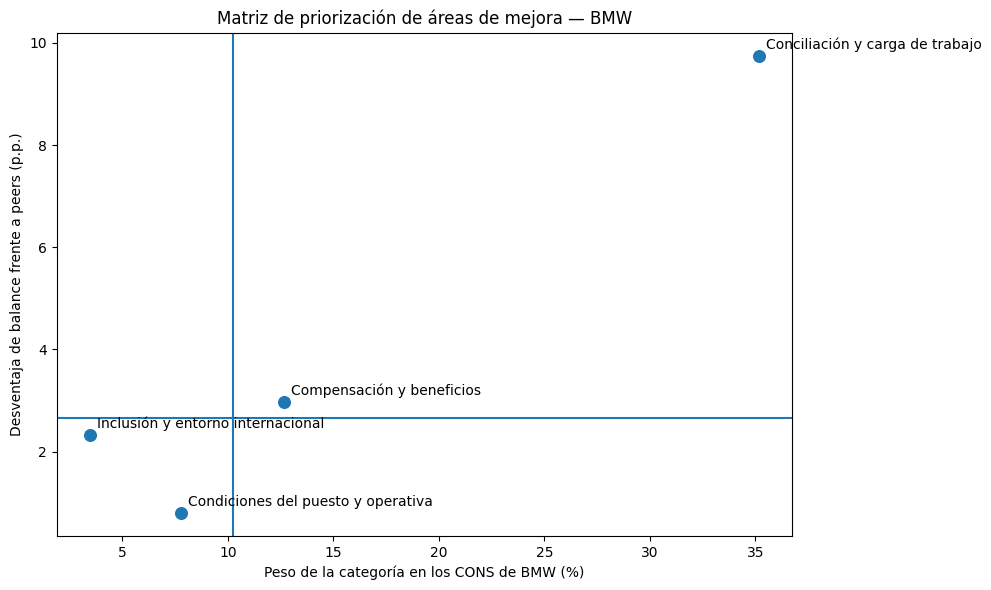

Debilidades relativas incluidas en la matriz:


,n_cons_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,desventaja_vs_peers,zona_orientativa
categoria,,,,,,
Conciliación y carga de trabajo,172,35.17,-26.61,-16.86,9.75,Alta atención: peso y desventaja elevados
Compensación y beneficios,62,12.68,-0.69,2.29,2.98,Alta atención: peso y desventaja elevados
Inclusión y entorno internacional,17,3.48,-3.48,-1.15,2.33,Vigilancia
Condiciones del puesto y operativa,38,7.77,-7.77,-6.98,0.79,Vigilancia


In [24]:
if "comparacion_bmw" in globals():
    priorizacion = comparacion_bmw[
        (comparacion_bmw["balance_neto_BMW"] < 0)
        & (comparacion_bmw["gap_balance_BMW_menos_peers"] < 0)
        & (comparacion_bmw["pct_cons_BMW"] > 0)
    ].copy()

    priorizacion["desventaja_vs_peers"] = (
        -priorizacion["gap_balance_BMW_menos_peers"]
    )

    if len(priorizacion) > 0:
        ref_peso = priorizacion["pct_cons_BMW"].median()
        ref_desventaja = priorizacion["desventaja_vs_peers"].median()

        ax = priorizacion.plot.scatter(
            x="pct_cons_BMW",
            y="desventaja_vs_peers",
            figsize=(10, 6),
            s=70,
        )

        for categoria, fila in priorizacion.iterrows():
            ax.annotate(
                categoria,
                (fila["pct_cons_BMW"], fila["desventaja_vs_peers"]),
                xytext=(5, 5),
                textcoords="offset points",
            )

        ax.axvline(ref_peso)
        ax.axhline(ref_desventaja)

        ax.set_title("Matriz de priorización de áreas de mejora — BMW")
        ax.set_xlabel("Peso de la categoría en los CONS de BMW (%)")
        ax.set_ylabel("Desventaja de balance frente a peers (p.p.)")
        plt.tight_layout()
        plt.show()

        priorizacion["zona_orientativa"] = np.select(
            [
                (priorizacion["pct_cons_BMW"] >= ref_peso)
                & (priorizacion["desventaja_vs_peers"] >= ref_desventaja),
                (priorizacion["pct_cons_BMW"] >= ref_peso)
                | (priorizacion["desventaja_vs_peers"] >= ref_desventaja),
            ],
            [
                "Alta atención: peso y desventaja elevados",
                "Atención: destaca en una dimensión",
            ],
            default="Vigilancia",
        )

        print("Debilidades relativas incluidas en la matriz:")
        display(
            priorizacion[
                [
                    "n_cons_BMW",
                    "pct_cons_BMW",
                    "balance_neto_BMW",
                    "balance_neto_Peers",
                    "desventaja_vs_peers",
                    "zona_orientativa",
                ]
            ]
            .sort_values(
                ["desventaja_vs_peers", "pct_cons_BMW"],
                ascending=False,
            )
            .round(2)
        )
    else:
        print("No aparecen debilidades relativas con balance BMW negativo.")
else:
    print("⏸ Matriz pendiente hasta completar el etiquetado de topics.")


---
## 10. Extra opcional: evolución temporal de categorías

El enunciado permite sumar valor estudiando la evolución de los principales temas. Una vez etiquetados, observaremos las categorías de cons de BMW por año.

Este análisis es descriptivo: una subida temporal no implica que un acontecimiento concreto sea la causa.

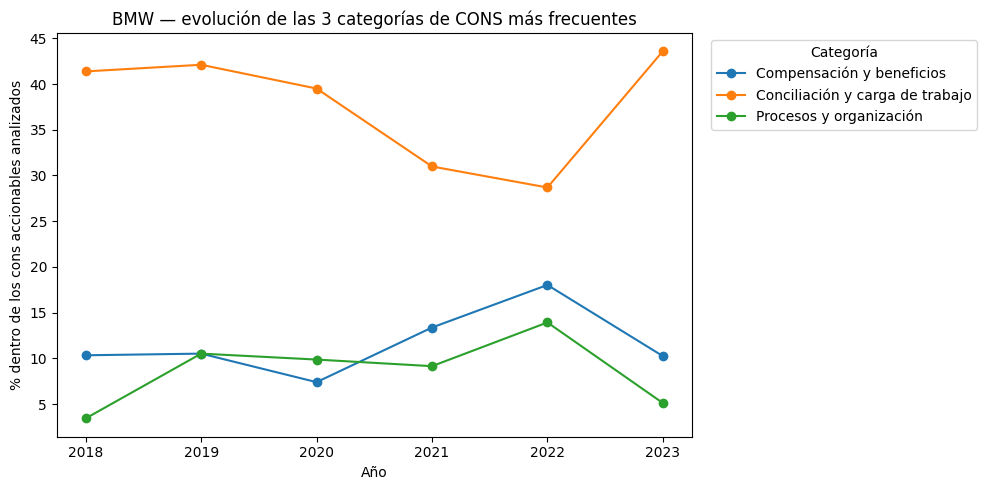

In [25]:
if not df_nlp["categoria_cons"].str.startswith("REVISAR").any():
    bmw_time = df_nlp[
        (df_nlp["firm"] == TARGET)
        & (~df_nlp["categoria_cons"].isin(CATEGORIAS_EXCLUIR_ANALISIS))
        & df_nlp["anio"].notna()
    ].copy()

    top3 = bmw_time["categoria_cons"].value_counts().head(3).index.tolist()
    total_anual = bmw_time.groupby("anio").size().rename("total")

    conteos = (
        bmw_time[bmw_time["categoria_cons"].isin(top3)]
        .groupby(["anio", "categoria_cons"])
        .size()
        .rename("n")
        .reset_index()
        .merge(total_anual.reset_index(), on="anio", how="left")
    )
    conteos["pct"] = conteos["n"] / conteos["total"] * 100

    temporal = (
        conteos.pivot(index="anio", columns="categoria_cons", values="pct")
        .fillna(0)
    )

    temporal.plot(marker="o", figsize=(10, 5))
    plt.title("BMW — evolución de las 3 categorías de CONS más frecuentes")
    plt.xlabel("Año")
    plt.ylabel("% dentro de los cons accionables analizados")
    plt.legend(title="Categoría", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("⏸ Evolución temporal pendiente hasta completar MAP_CONS.")


---
## 10.1 Resumen interpretado para orientar las recomendaciones

El resumen evita interpretar el resultado únicamente por el signo del gap. Se muestran cuatro bloques distintos:

1. **Fortalezas reales**: balance BMW y gap positivos.
2. **Debilidades relativas reales**: balance BMW y gap negativos.
3. **Ventajas relativas con balance BMW aún negativo**: BMW está mejor que peers, pero el tema sigue siendo una fricción.
4. **Oportunidades de employer branding**: señal positiva en BMW que los peers explotan todavía más.

Después triangulamos las debilidades con rating, recomendación y diferencias entre empleados actuales y antiguos.


In [26]:
if "comparacion_bmw" in globals():
    cols_resumen = [
        "n_pros_BMW", "n_cons_BMW",
        "pct_pros_BMW", "pct_cons_BMW",
        "balance_neto_BMW", "balance_neto_Peers",
        "gap_balance_BMW_menos_peers",
    ]

    print("Fortalezas reales de BMW:")
    display(fortalezas_reales[cols_resumen].round(2))

    print("\nDebilidades relativas reales de BMW:")
    display(debilidades_reales[cols_resumen].round(2))

    print("\nVentajas relativas con balance BMW todavía negativo:")
    display(ventajas_relativas[cols_resumen].round(2))

    print("\nOportunidades positivas donde los peers destacan más:")
    display(oportunidades_branding[cols_resumen].round(2))

    if "priorizacion" in globals() and len(priorizacion) > 0:
        print("\nCandidatas de la matriz de priorización:")
        display(
            priorizacion[
                ["n_cons_BMW", "pct_cons_BMW",
                 "desventaja_vs_peers", "zona_orientativa"]
            ]
            .sort_values(
                ["desventaja_vs_peers", "pct_cons_BMW"],
                ascending=False,
            )
            .round(2)
        )


Fortalezas reales de BMW:


,n_pros_BMW,n_cons_BMW,pct_pros_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,gap_balance_BMW_menos_peers
categoria,,,,,,,
"Marca, producto y propósito",204,28,31.78,5.73,26.05,18.27,7.78
Cultura y ambiente,203,31,31.62,6.34,25.28,23.87,1.41



Debilidades relativas reales de BMW:


,n_pros_BMW,n_cons_BMW,pct_pros_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,gap_balance_BMW_menos_peers
categoria,,,,,,,
Conciliación y carga de trabajo,55,172,8.57,35.17,-26.61,-16.86,-9.75
Compensación y beneficios,77,62,11.99,12.68,-0.69,2.29,-2.98
Inclusión y entorno internacional,0,17,0.00,3.48,-3.48,-1.15,-2.33
Condiciones del puesto y operativa,0,38,0.00,7.77,-7.77,-6.98,-0.79



Ventajas relativas con balance BMW todavía negativo:


,n_pros_BMW,n_cons_BMW,pct_pros_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,gap_balance_BMW_menos_peers
categoria,,,,,,,
Equipo y liderazgo,51,48,7.94,9.82,-1.87,-5.92,4.05
Procesos y organización,0,49,0.00,10.02,-10.02,-13.92,3.90
"Carrera, aprendizaje y desarrollo",37,44,5.76,9.00,-3.23,-3.67,0.44



Oportunidades positivas donde los peers destacan más:


,n_pros_BMW,n_cons_BMW,pct_pros_BMW,pct_cons_BMW,balance_neto_BMW,balance_neto_Peers,gap_balance_BMW_menos_peers
categoria,,,,,,,
Innovación y entorno dinámico,15,0,2.34,0.0,2.34,4.07,-1.73



Candidatas de la matriz de priorización:


,n_cons_BMW,pct_cons_BMW,desventaja_vs_peers,zona_orientativa
categoria,,,,
Conciliación y carga de trabajo,172,35.17,9.75,Alta atención: peso y desventaja elevados
Compensación y beneficios,62,12.68,2.98,Alta atención: peso y desventaja elevados
Inclusión y entorno internacional,17,3.48,2.33,Vigilancia
Condiciones del puesto y operativa,38,7.77,0.79,Vigilancia


---
## 10.2 Triangulación de evidencias para RRHH

La matriz responde a la pregunta exigida por el caso: **¿qué problemas tienen peso en BMW y además están peor que los peers?**

Para formular recomendaciones más robustas añadimos dos comprobaciones:

- **Severidad interna**: rating medio y % de recomendación cuando aparece cada categoría negativa.
- **Señal de salida**: diferencia entre antiguos y actuales de BMW, y diferencia entre antiguos de BMW y antiguos de los peers.

Esto permite distinguir, por ejemplo, una debilidad competitiva de una fricción interna relevante aunque BMW esté relativamente mejor que el mercado.


In [27]:
if all(
    nombre in globals()
    for nombre in ["comparacion_bmw", "contraste", "bmw_estado", "salida"]
):
    evidencia_rrhh = comparacion_bmw[
        [
            "n_cons_BMW",
            "pct_cons_BMW",
            "balance_neto_BMW",
            "gap_balance_BMW_menos_peers",
            "interpretacion",
        ]
    ].copy()

    evidencia_rrhh = evidencia_rrhh.join(
        contraste[["rating_medio", "pct_recomienda"]],
        how="left",
    )
    evidencia_rrhh = evidencia_rrhh.join(
        bmw_estado[["gap_antiguos_menos_actuales"]],
        how="left",
    )
    evidencia_rrhh = evidencia_rrhh.join(
        salida[["gap_BMW_menos_peers"]].rename(
            columns={
                "gap_BMW_menos_peers":
                "gap_antiguos_BMW_menos_peers"
            }
        ),
        how="left",
    )

    categorias_clave = [
        "Conciliación y carga de trabajo",
        "Compensación y beneficios",
        "Equipo y liderazgo",
        "Inclusión y entorno internacional",
        "Marca, producto y propósito",
        "Cultura y ambiente",
    ]

    print("Triangulación de categorías clave:")
    display(
        evidencia_rrhh
        .reindex(categorias_clave)
        .round(2)
    )


Triangulación de categorías clave:


,n_cons_BMW,pct_cons_BMW,balance_neto_BMW,gap_balance_BMW_menos_peers,interpretacion,rating_medio,pct_recomienda,gap_antiguos_menos_actuales,gap_antiguos_BMW_menos_peers
categoria,,,,,,,,,
Conciliación y carga de trabajo,172,35.17,-26.61,-9.75,Debilidad relativa,4.07,48.26,3.39,4.65
Compensación y beneficios,62,12.68,-0.69,-2.98,Debilidad relativa,3.95,50.00,-4.16,2.00
Equipo y liderazgo,48,9.82,-1.87,4.05,"Ventaja relativa, balance BMW aún negativo",3.08,27.08,4.24,-3.77
Inclusión y entorno internacional,17,3.48,-3.48,-2.33,Debilidad relativa,3.88,17.65,-1.17,-0.36
"Marca, producto y propósito",28,5.73,26.05,7.78,Fortaleza real,4.46,50.00,-1.00,-0.63
Cultura y ambiente,31,6.34,25.28,1.41,Fortaleza real,3.68,54.84,-0.42,-1.98


---
## 11. Conclusiones ejecutivas, recomendaciones y limitaciones

### Conclusiones ejecutivas

**1. BMW parte de una posición global sólida, pero la recomendación tiene margen de mejora.**  
El rating medio de BMW es aproximadamente **4,03**, por encima de la media de peers (~**3,84**). Sin embargo, el porcentaje que recomienda la empresa (**46,2 %**) queda ligeramente por debajo del promedio de peers (~**49,1 %**). Por tanto, el reto no parece ser una mala experiencia generalizada, sino determinadas fricciones concretas.

**2. La principal fortaleza diferencial es Marca, producto y propósito.**  
En BMW representa aproximadamente **31,8 % de los pros** y **5,7 % de los cons**, con un balance neto de **+26,05 p.p.** frente a **+18,27 p.p.** en los peers: un gap favorable de **+7,78 p.p.**.  
**Cultura y ambiente** también presenta un balance positivo (**+25,28 p.p.**) y ligeramente mejor que peers (**+1,41 p.p.**). Estas dos dimensiones son las fortalezas más defendibles para el employer branding de BMW.

**3. Conciliación y carga de trabajo es la prioridad más clara.**  
Concentra aproximadamente **35,2 % de los cons accionables** de BMW y su balance es **-26,61 p.p.**, frente a **-16,86 p.p.** en los peers. El gap de **-9,75 p.p.** es la mayor desventaja del análisis. Además, esta categoría aumenta entre antiguos frente a actuales de BMW (**+3,39 p.p.**) y pesa más entre antiguos BMW que entre antiguos de los peers (**+4,65 p.p.**). Es la señal que combina de forma más consistente frecuencia, desventaja competitiva y relación con salida.

**4. Compensación y beneficios es la segunda debilidad competitiva.**  
BMW presenta un balance de **-0,69 p.p.** frente a **+2,29 p.p.** en peers, con un gap de **-2,98 p.p.**. Entre antiguos empleados, BMW también supera a los peers en peso de esta queja (**+2,00 p.p.**). Sin embargo, dentro de BMW aparece menos entre antiguos que entre actuales, por lo que se interpreta mejor como una **desventaja de propuesta de valor al empleado** que como principal motivo interno de salida.

**5. Equipo y liderazgo requiere atención interna, aunque no sea una debilidad frente a peers.**  
BMW está mejor que los peers en esta dimensión (gap de balance **+4,05 p.p.**), pero su propio balance sigue siendo negativo (**-1,87 p.p.**). Cuando aparece la queja, el rating medio baja a aproximadamente **3,08** y solo **27,1 %** de esas reseñas recomienda BMW. Además, su peso aumenta entre antiguos frente a actuales (**+4,24 p.p.**). Por tanto, no es una fortaleza absoluta: es una fricción interna de alta severidad.

**6. Inclusión y entorno internacional es una señal a vigilar, no una prioridad principal.**  
Presenta un gap desfavorable (**-2,33 p.p.**) y baja recomendación entre las reseñas asociadas, pero el volumen BMW es reducido (**17 reseñas accionables**). Además, no emerge un topic positivo suficientemente específico para construir una contraparte perfectamente simétrica; parte de las menciones favorables relacionadas con inclusión puede quedar integrada en **Cultura y ambiente**. Por ello se conserva como señal secundaria que requiere más datos antes de justificar una intervención amplia.

### Tres recomendaciones concretas para RRHH

**Recomendación 1 — Reducir fricciones de carga de trabajo y conciliación.**  
Realizar un diagnóstico por áreas/equipos para localizar concentración de horas extra, picos de carga, turnos y necesidades de flexibilidad. Empezar con un piloto en las unidades con mayor señal y medir antes/después.  
**Indicadores sugeridos:** peso de la categoría en `cons`, horas extra, absentismo, pulse survey de conciliación y rotación no deseada. Los indicadores internos no están disponibles en Glassdoor y se proponen como validación posterior.

**Recomendación 2 — Revisar competitividad de compensación y beneficios de forma segmentada.**  
Contrastar salario fijo, variable y beneficios frente al mercado en perfiles críticos, países y funciones comparables. La evidencia no justifica una subida salarial general indiscriminada; sí un **benchmarking dirigido** y ajustes donde exista una brecha real.  
**Indicadores sugeridos:** quejas de compensación, aceptación de ofertas, salidas vinculadas a remuneración y posición salarial frente a benchmarks externos.

**Recomendación 3 — Reforzar calidad de liderazgo en los equipos con peores señales.**  
Usar encuestas internas, feedback 360º y datos de rotación para localizar equipos donde liderazgo/management coincida con baja recomendación. Aplicar coaching o formación específica a managers y seguir la evolución.  
**Indicadores sugeridos:** puntuación de liderazgo, recomendación interna, rotación por manager/equipo y peso de `Equipo y liderazgo` entre antiguos empleados.

### Implicación para employer branding

Sin convertirla en una cuarta recomendación, el análisis identifica un activo claro que RRHH puede comunicar de forma creíble: **marca, producto y propósito**, apoyado por **cultura y ambiente**. La comunicación externa debería apoyarse en fortalezas que realmente aparecen en las reseñas, evitando promesas que contradigan las áreas de mejora detectadas.

### Limitaciones

- Las reseñas de Glassdoor son **autoseleccionadas** y no representan necesariamente a toda la plantilla.
- El dataset mezcla países, funciones y unidades de negocio; parte de las diferencias puede reflejar composición de las muestras.
- La selección de peers combina comparabilidad sectorial con disponibilidad suficiente de reseñas; otras selecciones razonables podrían cambiar los gaps.
- BERTopic agrupa textos por similitud semántica y su traducción a categorías de negocio requiere **revisión humana**.
- Se conservan outliers como `Sin tema claro` en lugar de forzar asignaciones.
- Los porcentajes accionables excluyen outliers y comentarios sin contenido útil; por ello se reporta la cobertura.
- Sentimiento, topics, ratings y gaps describen **asociaciones**, no causalidad.
- Los años extremos de la ventana temporal son parciales.
- Las recomendaciones deben contrastarse con datos internos de clima, compensación, carga de trabajo y rotación antes de tomar decisiones de alto coste.

### Próximos pasos

1. **Contrastar los hallazgos con datos internos de RRHH**: clima, horas extra, compensación, absentismo, rotación y feedback de managers.
2. **Replicar el análisis por país, función o unidad de negocio** si esos datos estuvieran disponibles, para comprobar si las señales se concentran en colectivos concretos.
3. **Monitorizar en el tiempo las categorías prioritarias** para evaluar si las acciones propuestas reducen el peso de conciliación, compensación y liderazgo en las reseñas negativas.
4. Preparar la presentación ejecutiva centrada en el problema de negocio, las fortalezas diferenciales, las tres prioridades y las acciones recomendadas.
